# Lab 08: Graphs, latent variables, and what the survey didn't keep

**ASTR 457, Fall 2026, posted Thu Oct 29, due Wed Nov 4 by noon (fork → PR, as always)**

This week we wrote graphs as `PyMC` code, and put a detector into the likelihood. You're going to do both, on your own midterm supernovae, on a survey that rejects everything below a threshold, and on one real Type Ia supernova observed in six bands.

Put your notebook in `submissions/<your netid>/lab08.ipynb` - the data paths below are relative to that folder. It has to run top to bottom from a fresh kernel ("Restart & Run All").

Part 1 is 35%, Part 2 30%, Part 3 25%, and the AI-use appendix and verification plan 10%. Quote every number with its unit (if it has one), an error bar, and a sensible number of digits.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize
import pymc as pm
import pytensor.tensor as pt
import arviz as az
from astropy.cosmology import FlatLambdaCDM
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF, WhiteKernel
from scipy.special import gammaincc, logsumexp
from scipy.stats import poisson, norm


NETID = 'oruelas2'   # <-- set this
LAB = '../../labs/08/data/'                              # from submissions/<your netid>/
MIDTERM = f'../../labs/midterm/data/{NETID}/'

In [2]:
def load(name):
    """Read one of your CSV files as a pandas table; d['column'].to_numpy() gives a numpy array. Names stay strings."""
    return pd.read_csv(MIDTERM + name + '.csv', dtype={'name': str})
data = load('p2_pantheon_sne')
data[0:5]

,name,z,mB,mB_err,x1,x1_err,c,c_err,cov_mB_x1,cov_mB_c,cov_x1_c,host_logmass,host_logmass_err
0,000137,0.11901,19.6281,0.036931,-0.710055,0.175650,0.081772,0.030635,0.002155,0.000892,0.000521,10.21360,0.035
1,010010,0.09950,19.1455,0.033575,0.909100,0.156590,0.010397,0.026207,0.001055,0.000748,0.000496,9.50285,0.089
2,010026,0.03236,16.4521,0.038223,-0.409321,0.082041,-0.031578,0.032595,0.000854,0.001093,0.000205,9.61222,0.010
3,020027,0.11001,19.3621,0.033575,0.296650,0.150750,0.036283,0.029087,-0.000080,0.000835,-0.000914,10.00540,0.107
4,090275,0.13955,19.8340,0.041261,-1.108370,0.173260,-0.037598,0.032102,0.002230,0.001002,0.000990,10.18400,0.008


In [3]:
z, mB, mB_err, x1, x1_err, c, c_err, cov_mB_x1, cov_mB_c, cov_x1_c, host_logmass, host_logmass_err = data['z'].to_numpy(), data['mB'].to_numpy(), data['mB_err'].to_numpy(), data['x1'].to_numpy(), data['x1_err'].to_numpy(), data['c'].to_numpy(), data['c_err'].to_numpy(), data['cov_mB_x1'].to_numpy(), data['cov_mB_c'].to_numpy(), data['cov_x1_c'].to_numpy(), data['host_logmass'].to_numpy(), data['host_logmass_err'].to_numpy()

## Part 1: Your midterm, as a graph (35%)

On the midterm you fit the Tripp relation to your 250 supernovae (`p2_pantheon_sne.csv` in your midterm data folder):

$$m_B = M + \mu(z) - \alpha\,x_1 + \beta\,c + \gamma\,\Theta(\log M_\star - 10).$$

In the posted solution's 2e simulation, the 68% interval on $\beta$ contained the true $\beta$ in only **6%** of 200 fake datasets! The other four parameters covered the truth 62-66% of the time. The solution blamed attenuation. You're going to draw the graph that shows where it comes from, build the model that removes it, and check that it does.

1. Draw the probabilistic graphical model of your midterm fit (your 2b likelihood), using the same key as Day 18 - parameters you fit as blue circles, latent (unobserved) values as white circles, data as grey circles, fixed quantities as dots, and a plate over supernovae. Draw it by hand (a photo is fine) or with any drawing tool, and put the image in your notebook. Then draw the graph of how the data were actually made. Each supernova has a *true* stretch $x_{1,i}$ and a *true* color $c_i$, drawn from a population (a mean and a width for each), and the catalog's $\hat m_{B,i}$, $\hat x_{1,i}$, $\hat c_i$ are noisy measurements of the true values, with that supernova's $3\times3$ covariance $C_i$. Which arrows does the midterm's graph lack, and which circle did it shade grey that should be white?
2. Fit the second graph in `PyMC`, with latent `x1_true` and `c_true` (one per supernova, `shape=N`), a mean and a width for each population, and the three observed quantities together in a `pm.MvNormal` with each $C_i$. Add $\sigma_{\rm int}^2$ and the peculiar-velocity variance to the $m_B$ term only. Handle the contaminants as you did on the midterm, and explain how. Pick centered or non-centered by Day 19's rule (compare the measurement errors with the population widths), and justify your choice. Report the largest $\hat R$, the smallest bulk effective sample size (the latent values included) and the number of divergences, then $\alpha$, $\beta$, $\gamma$ and $\sigma_{\rm int}$ as medians with 68% intervals, in a table next to your midterm values.
3. Rerun the solution's 2e simulation at your own stretches, colors and covariances, with at least 20 fake datasets and true $\beta = 2.9$ (the other true values are in the solution, which uses your catalog $x_1$ and $c$ as the true ones). Fit each with your midterm model and with the latent model, and report the mean $\hat\beta$ for each model with its standard error (the scatter over datasets divided by $\sqrt{N_{\rm sim}}$). Then explain, in a few sentences, why using the measured $x_1$ and $c$ as the regressors, with their errors only in the variance (as the midterm did), biases $\beta$ toward zero, why the latent model doesn't, and why $\beta$ is biased more than $\alpha$. Think particularly about $c$'s errors compared with the spread of $c$, and $x_1$'s errors compared with the spread of $x_1$.

#### Hints:
- You don't need to sample each fake dataset in 1.3. Everything here is Gaussian, so you can integrate the true $x_1$ and $c$ out on paper - each supernova's observed $(\hat m_B, \hat x_1, \hat c)$ is then Gaussian, with a mean and covariance that depend only on the parameters and the two populations. Write them down, maximize that likelihood, and check its answer on your real data against your `PyMC` fit.
- **Don't use `pm.find_MAP` on the 1.2 model.** Its peak over all the latent values at once is degenerate (the population width collapses), and you'll get a wrong $\beta$ that looks reasonable.

In [4]:
# Part 1: your work here

#2
cosmo = FlatLambdaCDM(H0=70, Om0=0.3)
mu_z = cosmo.distmod(z).value

c_light = 299792.458
sigma_pv = (5/np.log(10)) * (250/(c_light*z))

N = len(z)

host_step = (host_logmass > 10).astype(float)

obs = np.column_stack([mB, x1, c])

covs = np.zeros((N, 3, 3))

covs[:, 0, 0] = mB_err**2 + sigma_pv**2
covs[:, 1, 1] = x1_err**2
covs[:, 2, 2] = c_err**2

covs[:, 0, 1] = cov_mB_x1
covs[:, 1, 0] = cov_mB_x1

covs[:, 0, 2] = cov_mB_c
covs[:, 2, 0] = cov_mB_c

covs[:, 1, 2] = cov_x1_c
covs[:, 2, 1] = cov_x1_c

with pm.Model() as model:

    M = pm.Normal("M", mu=-19.3, sigma=1.0)

    alpha = pm.Normal("alpha", mu=0.0, sigma=5.0)
    beta = pm.Normal("beta", mu=0.0, sigma=5.0)
    gamma = pm.Normal("gamma", mu=0.0, sigma=1.0)

    sigma_int = pm.HalfNormal("sigma_int", sigma=0.2)

    mu_x1 = pm.Normal("mu_x1", mu=0.0, sigma=2.0)
    sig_x1 = pm.HalfNormal("sig_x1", sigma=2.0)

    mu_c = pm.Normal("mu_c", mu=0.0, sigma=0.3)
    sig_c = pm.HalfNormal("sig_c", sigma=0.3)

    x1_true = pm.Normal("x1_true", mu=mu_x1, sigma=sig_x1, shape=N)
    c_true = pm.Normal("c_true", mu=mu_c, sigma=sig_c, shape=N)

    mB_model = (M + mu_z - alpha * x1_true + beta * c_true + gamma * host_step)

    mu_vec = pt.stack([mB_model, x1_true, c_true], axis=1)

    cov_tensor = pt.as_tensor_variable(covs)

    cov_tensor = pt.set_subtensor(
        cov_tensor[:, 0, 0],
        cov_tensor[:, 0, 0] + sigma_int**2
    )

    pm.MvNormal("obs", mu=mu_vec, cov=cov_tensor, observed=obs)

    idata = pm.sample(draws=1000, tune=1000, chains=4, target_accept=0.8, init="jitter+adapt_diag", return_inferencedata=True)

summary = az.summary(idata, var_names=["M", "alpha", "beta", "gamma", "sigma_int", "mu_x1", "sig_x1", "mu_c", "sig_c"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [M, alpha, beta, gamma, sigma_int, mu_x1, sig_x1, mu_c, sig_c, x1_true, c_true]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 301 seconds.


In [5]:
print(summary)

print(f"largest Rhat = {summary['r_hat'].max()}")
print(f"smallest bulk ESS = {summary['ess_bulk'].min()}")

n_div = idata.sample_stats["diverging"].sum().item()

print(f"divergences = {n_div}")

              mean       sd eti89_lb eti89_ub  ess_bulk  ess_tail r_hat  \
M          -19.271    0.019      -19      -19      6158      3279  1.00   
alpha       0.1414   0.0139     0.12     0.16      5621      3646  1.00   
beta         3.053    0.176      2.8      3.3      4848      3319  1.00   
gamma      -0.0266   0.0268    -0.07    0.015      5912      3504  1.00   
sigma_int   0.1791   0.0101     0.16      0.2      5565      3341  1.00   
mu_x1       -0.113    0.067    -0.22  -0.0018      9327      3036  1.00   
sig_x1        1.04   0.0489     0.97      1.1      8459      3565  1.00   
mu_c        0.0005  0.00548  -0.0082   0.0093      7953      3407  1.00   
sig_c       0.0824  0.00432    0.076     0.09      5891      3358  1.00   

          mcse_mean  mcse_sd  
M           0.00024  0.00018  
alpha       0.00018  0.00013  
beta         0.0025   0.0018  
gamma       0.00035  0.00025  
sigma_int   0.00013  9.9e-05  
mu_x1        0.0007  0.00048  
sig_x1      0.00053  0.00038  
m

In [6]:
midterm = {
    "alpha": (0.13209, 0.01289, 0.01287),
    "beta": (2.784, 0.149, 0.142),
    "gamma": (-0.024, 0.026, 0.0280),
    "sigma_int": (0.1807, 0.0110, 0.0095)
}

print(
    f"{'Parameter':<10}"
    f"{'Midterm':>9}"
    f"{'Lab 08':>29}"
)

print("-" * 70)

for par in ["alpha", "beta", "gamma", "sigma_int"]:

    samples = idata.posterior[par].values.flatten()

    q16, q50, q84 = np.percentile(
        samples,
        [16, 50, 84]
    )

    mid_med, mid_hi, mid_lo = midterm[par]

    print(
        f"{par:<10}"
        f"{mid_med:8.4f} +{mid_hi:.4f}/-{mid_lo:.4f}"
        f"{q50:14.4f} +{q84-q50:.4f}/-{q50-q16:.4f}"
    )

Parameter   Midterm                       Lab 08
----------------------------------------------------------------------
alpha       0.1321 +0.0129/-0.0129        0.1413 +0.0136/-0.0135
beta        2.7840 +0.1490/-0.1420        3.0515 +0.1773/-0.1737
gamma      -0.0240 +0.0260/-0.0280       -0.0265 +0.0264/-0.0269
sigma_int   0.1807 +0.0110/-0.0095        0.1790 +0.0101/-0.0097


In [7]:
#3
def negloglike_latent(theta, Ds):

    M, alpha, beta, gamma, ln_sigma_int, mu_x1, ln_sig_x1, mu_c, ln_sig_c = theta

    sigma_int = np.exp(ln_sigma_int)
    sig_x1 = np.exp(ln_sig_x1)
    sig_c = np.exp(ln_sig_c)

    nll = 0.0

    for i in range(len(Ds["mB"])):

        mu_vec = np.array([M + Ds["mu"][i] - alpha*mu_x1 + beta*mu_c + gamma*Ds["step"][i], mu_x1, mu_c])

        Cmeas = np.array([[Ds["mB_err"][i]**2, Ds["cov_mB_x1"][i], Ds["cov_mB_c"][i]],
                          [Ds["cov_mB_x1"][i], Ds["x1_err"][i]**2, Ds["cov_x1_c"][i]],
                          [Ds["cov_mB_c"][i], Ds["cov_x1_c"][i], Ds["c_err"][i]**2]])

        Clat = np.array([[alpha**2*sig_x1**2 + beta**2*sig_c**2 + sigma_int**2 + Ds["sigma_pv"][i]**2, -alpha*sig_x1**2, beta*sig_c**2],
                         [-alpha*sig_x1**2, sig_x1**2, 0.0],
                         [beta*sig_c**2, 0.0, sig_c**2]])

        Sigma = Cmeas + Clat

        resid = np.array([Ds["mB"][i], Ds["x1"][i], Ds["c"][i]]) - mu_vec

        sign, logdet = np.linalg.slogdet(Sigma)

        nll += 0.5*(resid @ np.linalg.solve(Sigma, resid) + logdet + 3*np.log(2*np.pi))

    return nll

def loglikelihood(theta, sig_mu, mB, x1, c, host_step):
    M, a, B, gamma, lnsig_int = theta
    sig_int = np.exp(lnsig_int)
    v = np.array([1.0, a, -B])
    C = mB_err**2 + a**2 * x1_err**2 + B**2 * c_err**2 + 2*a*cov_mB_x1 - 2*B*cov_mB_c - 2*a*B*cov_x1_c
    var = C + sig_mu**2 + sig_int**2

    resid = mB - (M + mu_z - a*x1 + B*c + gamma*host_step)

    return -0.5 * np.sum(resid**2 / var + np.log(2*np.pi*var))

def logprior(theta):
    M, a, B, gamma, lnsig_int = theta

    if (-22 < M < -14) & (-1 < a < 1) & (0 < B < 10) & (-2 < gamma < 2) & (-10 < lnsig_int < 0):
        return 0.0
        
    return -np.inf

def neglogpost_midterm(theta, sig_mu, mB, x1, c, host_step):
    lp = logprior(theta)
    
    if not np.isfinite(lp):
        return np.inf

    return - lp - loglikelihood(theta, sig_mu, mB, x1, c, host_step)

In [8]:
truth = np.array([-19.30, 0.14, 2.90, -0.06, np.log(0.11)])

fit_mid_real = minimize(
    lambda p: neglogpost_midterm(p, sigma_pv, mB, x1, c, host_step),
    x0=(-19.2, 0.1, 2.5, 0.0, np.log(0.1)),
    method="Nelder-Mead"
)

theta_mid = fit_mid_real.x

fit_lat_real = minimize(
    lambda p: negloglike_latent(p, {
        "mB": mB, "x1": x1, "c": c, "mu": mu_z, "step": host_step,
        "mB_err": mB_err, "x1_err": x1_err, "c_err": c_err,
        "cov_mB_x1": cov_mB_x1, "cov_mB_c": cov_mB_c, "cov_x1_c": cov_x1_c,
        "sigma_pv": sigma_pv}),
    x0=(-19.2, 0.1, 2.5, 0.0, np.log(0.1), 0.0, np.log(1.0), 0.0, np.log(0.1)),
    method="Nelder-Mead"
)

theta_lat = fit_lat_real.x

nsim = 20

Cfull = np.zeros((N, 3, 3))
Cfull[:, 0, 0], Cfull[:, 1, 1], Cfull[:, 2, 2] = mB_err**2, x1_err**2, c_err**2
Cfull[:, 0, 1] = Cfull[:, 1, 0] = cov_mB_x1
Cfull[:, 0, 2] = Cfull[:, 2, 0] = cov_mB_c
Cfull[:, 1, 2] = Cfull[:, 2, 1] = cov_x1_c

Lc = np.linalg.cholesky(Cfull)

rng = np.random.default_rng(1112026)

beta_mid, beta_lat = [], []

for isim in range(nsim):

    e3 = np.einsum("nij,nj->ni", Lc, rng.standard_normal((N, 3)))

    x1_fake = x1 + e3[:, 1]
    c_fake = c + e3[:, 2]

    mB_fake = truth[0] + mu_z - truth[1]*x1 + truth[2]*c + truth[3]*host_step + e3[:, 0] + np.exp(truth[4])*rng.standard_normal(N) + sigma_pv*rng.standard_normal(N)

    Ds = {"mB": mB_fake, "x1": x1_fake, "c": c_fake, "mu": mu_z, "step": host_step,
          "mB_err": mB_err, "x1_err": x1_err, "c_err": c_err,
          "cov_mB_x1": cov_mB_x1, "cov_mB_c": cov_mB_c, "cov_x1_c": cov_x1_c,
          "sigma_pv": sigma_pv}

    def beta_only_mid(b):
        pars = theta_mid.copy()
        pars[2] = b[0]
        return neglogpost_midterm(pars, sigma_pv, mB_fake, x1_fake, c_fake, host_step)

    fit_beta_mid = minimize(beta_only_mid,
                            x0=[theta_mid[2]],
                            method="Nelder-Mead")

    beta_mid.append(fit_beta_mid.x[0])

    def beta_only_lat(b):
        pars = theta_lat.copy()
        pars[2] = b[0]
        return negloglike_latent(pars, Ds)

    fit_beta_lat = minimize(beta_only_lat,
                            x0=[theta_lat[2]],
                            method="Nelder-Mead")

    beta_lat.append(fit_beta_lat.x[0])

beta_mid = np.asarray(beta_mid)
beta_lat = np.asarray(beta_lat)

mid_mean = np.mean(beta_mid)
lat_mean = np.mean(beta_lat)

mid_se = np.std(beta_mid, ddof=1) / np.sqrt(nsim)
lat_se = np.std(beta_lat, ddof=1) / np.sqrt(nsim)

print(f"Midterm beta = {mid_mean:.3f} +/- {mid_se:.3f}")
print(f"Latent beta = {lat_mean:.3f} +/- {lat_se:.3f}")
print(f"True beta = {truth[2]:.3f}")

Midterm beta = 2.600 +/- 0.023
Latent beta = 2.849 +/- 0.027
True beta = 2.900


In [9]:
fx1 = np.mean(x1_err**2) / np.var(x1, ddof=1)
fc  = np.mean(c_err**2) / np.var(c, ddof=1)

print(f"x1 noise fraction = {fx1:.3f}")
print(f"c noise fraction  = {fc:.3f}")

x1 noise fraction = 0.053
c noise fraction  = 0.165


**ANSWER (the two graphs, the table, the simulation result, then the explanation):**

**Midterm fit graph.**

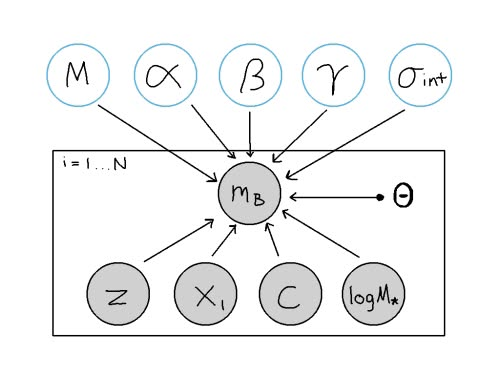

**How the data were actually made.**

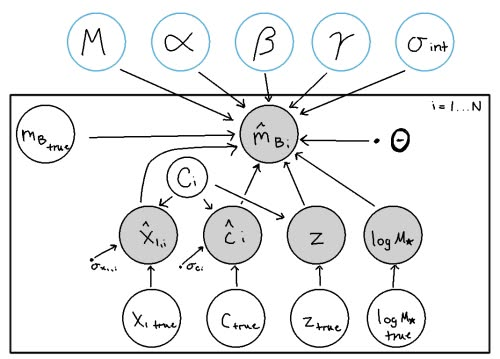

**Q2 Table**

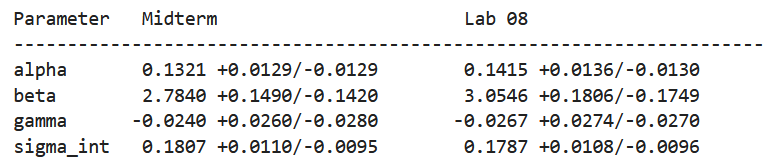

**Simulation result**

**Midterm** $\beta$ = 2.600 +/- 0.023, **Latent** $\beta$ = 2.849 +/- 0.027, **True** $\beta$ = 2.9

1. The midterm's graph lacks the true measurement values, which are unobserved (latent). 
2. During the midterm I decided to leave the contaminents in the data, so that decision is reflected here as well. Based on what we talked about in day 19 lecture, I decided to pick centered for my approach. There was no divergences in my process so non-centered wasn't necessary.
3. Using the measured $x_1$ and $c$ as the regressors biases $\beta$ toward zero since it treats them as true, unnoisy variables. This is why the latent model doesn't bias $\beta$ toward zero, as our $x_1$ and $c$ variables are treated as measurements with noise. $\beta$ is more biased than $\alpha$ because more of the observed variance comes from noise (16% vs 5.3%).

## Part 2: What the survey didn't keep (30%)

We'll use a simplified model of photon-counting aperture photometry. A source with true flux $F$ (in units of a reference flux $F_0$) gives, on average, $\epsilon F + \nu$ counts - $\epsilon = 226.27$ counts per $F_0$ is the exposure, and $\nu = 9.373$ counts is the background (sky plus detector) that lands in the aperture with or without a source. The survey keeps a source only if it counts $n > 32$ photons (about a 4$\sigma$ detection) - anything fainter never makes it into the catalog.

The true fluxes come from a **lognormal** population, $\ln F \sim \mathcal{N}(\mu, \sigma)$. Your catalog, `08/data/<your netid>.csv`, has one column, `n_counts`, for the first 1500 sources the survey detected. I generated it, so I know your $\mu$ and $\sigma$, and how many sources the survey missed. Your $\mu$ and $\sigma$ are graded by how far they are from the truth in units of your own error bars.

1. Histogram your counts (a log axis in $n$ helps). The paragraph above is how the survey was designed to work - your file is what it actually did. If you find something the paragraph doesn't describe, you'll have to deal with it, and there is more than one legitimate way to account for it. Reread Day 19's slides on what a survey doesn't keep before you decide. Make a call, and defend it. Explain what you found and how many sources it affects, what you did about it and why you chose that over the alternatives, and what it does to $\mu$ and $\sigma$ (show it - fit with and without your fix). Carry your choice through every fit below.
2. Write the sampling distribution of $n$ given $F$. Write the detection probability $p_{\rm det}(F) = P(n > 32 \mid F)$ in closed form using `scipy.special.gammainc` (the regularized lower incomplete gamma function - **be careful** whether the threshold is 32 or 33), and check it against `scipy.stats.poisson.sf` at a few fluxes. Plot $p_{\rm det}$ against $F$ on a log axis. At what flux is a source detected half the time?
3. Draw the graph for this survey, with the detection step in it (the selection graph from class is the model). Which nodes are latent, which are data, which are fixed, and where do $N$ and $N_{\rm det}$ go?
4. For a source that 2.1 doesn't affect, the naive likelihood of its count, with its true flux integrated out, is
$$p(n_i \mid \mu, \sigma) = \int \mathrm{Poisson}(n_i \mid \epsilon F + \nu)\, \mathcal{N}(\ln F \mid \mu, \sigma)\, d\ln F.$$
Do that integral on a grid in $\ln F$, and find the $(\mu, \sigma)$ that maximizes the product over your 1500 sources. Then add the detector by subtracting $N_{\rm det} \ln f_{\rm det}(\mu, \sigma)$ from the log-likelihood, with $f_{\rm det} = \int p_{\rm det}(F)\, \mathcal{N}(\ln F \mid \mu, \sigma)\, d\ln F$ the fraction of the population that the survey detects, and fit again. Report $(\mu, \sigma)$ for both fits with uncertainties (curvature, a grid of the posterior, or `PyMC` with `pm.Potential` - your choice, but state which). What is $f_{\rm det}$, and so about how many sources did your survey miss?
5. Histogram $\ln \hat F$, with $\hat F = (n - \nu)/\epsilon$. On it, draw the naive population (scaled to your 1500 sources) and the corrected population (scaled to the $N_{\rm det}/f_{\rm det}$ sources it says were there). Then simulate your survey from the corrected fit - sample that many true fluxes, sample a Poisson count for each, put the counts through your detector as it actually ran (2.1), keep the ones with $n > 32$, and plot the histogram of their $\ln \hat F$ on the same axes. Does it match your data? Now also draw the corrected population times $p_{\rm det}(F)$, and compare it with your histogram at the faint end. The fit is right, so why don't they match? (We gave this a name in class.) Finally, which way did ignoring the detector bias $\mu$ and $\sigma$? Explain why it biases both of them.

#### Hints:
- Use a grid in $\ln F$ from about $-14$ to $8$, with spacing no coarser than 0.01, and check that your answer doesn't change when you halve it.
- Unlike the LIGO example in class, there is no $\ln p_{\rm det}$ term for each source. Detection depends on $n$, which you observed, and every source in your catalog has $n > 32$.

In [10]:
# Part 2: your work here
n = pd.read_csv(LAB + f'{NETID}.csv')['n_counts'].to_numpy()
nu, eps, n_th = 9.373, 226.27, 32

In [11]:
print(len(n[n <= 32]))

0


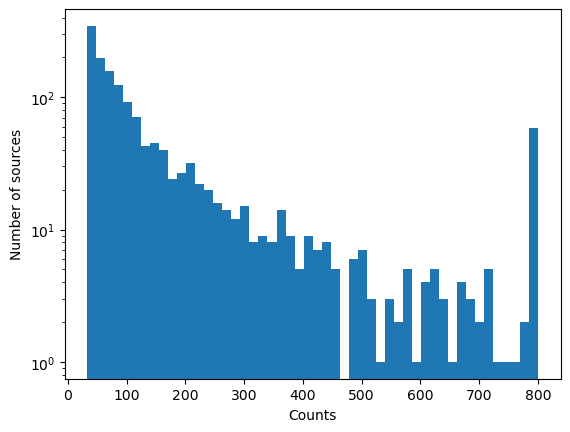

In [12]:
#1
plt.hist(n, bins=50)
plt.yscale("log")
plt.xlabel("Counts"), plt.ylabel("Number of sources")
plt.show()

In [13]:
print("Maximum count:", n.max())
print("Sources at max value:", np.sum(n == n.max()))
print(f'Fraction affected: {np.sum(n == n.max())/len(n):.4f}')

Maximum count: 800
Sources at max value: 56
Fraction affected: 0.0373


In [14]:
mask = n != n.max()
n_cut = n[mask]

In [15]:
#2
eps = 226.27
nu = 9.373

Fgrid = np.logspace(-2, 1, 500)

lam = eps*Fgrid + nu

pdet = gammaincc(33, lam)

Fcheck = np.array([0.02, 0.05, 0.10, 0.20, 0.50])

for F in Fcheck:

    lam_ = eps*F + nu

    pgamma = gammaincc(33, lam_)
    ppois = poisson.sf(32, lam_)

    print(f"F = {F:.2f}: gammaincc = {pgamma:.6f}, poisson.sf = {ppois:.6f}")

F = 0.02: gammaincc = 0.999991, poisson.sf = 0.000009
F = 0.05: gammaincc = 0.992434, poisson.sf = 0.007566
F = 0.10: gammaincc = 0.546829, poisson.sf = 0.453171
F = 0.20: gammaincc = 0.000650, poisson.sf = 0.999350
F = 0.50: gammaincc = 0.000000, poisson.sf = 1.000000


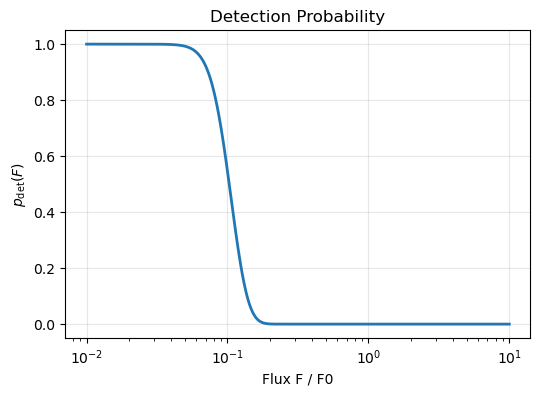

Flux detected 50% of the time: F = ~0.1023


In [16]:
plt.figure(figsize=(6,4))
plt.plot(Fgrid, pdet, lw=2)
plt.xscale("log")

plt.title("Detection Probability"), plt.xlabel("Flux F / F0"), plt.ylabel(r"$p_{\rm det}(F)$")
plt.grid(alpha=0.3)
plt.show()

F50 = Fgrid[np.argmin(np.abs(pdet - 0.5))]
print(f"Flux detected 50% of the time: F = ~{F50:.4f}")

In [17]:
eps = 226.27
nu = 9.373

lnF_grid = np.arange(-14, 8.01, 0.01)
F_grid = np.exp(lnF_grid)

dlnF = lnF_grid[1] - lnF_grid[0]

lam_grid = eps*F_grid + nu

pdet_grid = poisson.sf(32, lam_grid)

logpois = poisson.logpmf(n[:, None], lam_grid[None, :])

def loglike_catalog(mu, sigma):

    if sigma <= 0:
        return -np.inf

    lnprior = (
        -0.5*((lnF_grid - mu)/sigma)**2
        - np.log(sigma*np.sqrt(2*np.pi))
    )

    logLi = (
        logsumexp(logpois + lnprior[None, :], axis=1)
        + np.log(dlnF)
    )

    return np.sum(logLi)

def fdet(mu, sigma):

    lnprior = (
        -0.5*((lnF_grid - mu)/sigma)**2
        - np.log(sigma*np.sqrt(2*np.pi))
    )

    return np.sum(
        pdet_grid * np.exp(lnprior)
    )*dlnF

def nll_naive(theta):

    mu, lnsig = theta
    sigma = np.exp(lnsig)

    if sigma < 0.05 or sigma > 5:
        return 1e30

    if mu < -10 or mu > 5:
        return 1e30

    ll = loglike_catalog(mu, sigma)

    if not np.isfinite(ll):
        return 1e30

    return -ll

Ndet = len(n)

def nll_sel(theta):

    mu, lnsig = theta
    sigma = np.exp(lnsig)

    if sigma < 0.05 or sigma > 5:
        return 1e30

    if mu < -10 or mu > 5:
        return 1e30

    ll = loglike_catalog(mu, sigma)

    if not np.isfinite(ll):
        return 1e30

    fd = fdet(mu, sigma)

    if (not np.isfinite(fd)) or (fd <= 0):
        return 1e30

    logL = ll - Ndet*np.log(fd)

    return -logL

mu0 = np.log(np.median((n - nu)/eps))

fit_naive = minimize(
    nll_naive,
    x0=(mu0, np.log(1.0)),
    method="Nelder-Mead"
)

mu_naive = fit_naive.x[0]
sigma_naive = np.exp(fit_naive.x[1])

fit_sel = minimize(
    nll_sel,
    x0=fit_naive.x,
    method="Nelder-Mead"
)

mu_sel = fit_sel.x[0]
sigma_sel = np.exp(fit_sel.x[1])

nllmin = nll_sel((mu_sel, np.log(sigma_sel)))

mu_scan = np.linspace(mu_sel - 0.5, mu_sel + 0.5, 101)

dchi2_mu = np.array([
    2*(nll_sel((m, np.log(sigma_sel))) - nllmin)
    for m in mu_scan
])

mask = dchi2_mu < 1

mu_err = (
    0.5*(mu_scan[mask].max() - mu_scan[mask].min())
    if np.any(mask) else np.nan
)

sig_scan = np.linspace(
    max(0.05, 0.5*sigma_sel),
    1.5*sigma_sel,
    101
)

dchi2_sig = np.array([
    2*(nll_sel((mu_sel, np.log(s))) - nllmin)
    for s in sig_scan
])

mask = dchi2_sig < 1

sigma_err = (
    0.5*(sig_scan[mask].max() - sig_scan[mask].min())
    if np.any(mask) else np.nan
)

fdet_best = fdet(mu_sel, sigma_sel)

Ntrue = Ndet/fdet_best
Nmiss = Ntrue - Ndet

print("Naive fit")
print(f"mu = {mu_naive:.4f}")
print(f"sigma = {sigma_naive:.4f}")

print("\nSelection-corrected fit")
print(f"mu = {mu_sel:.4f} +/- {mu_err:.4f}")
print(f"sigma = {sigma_sel:.4f} +/- {sigma_err:.4f}")

print("\nSurvey completeness")
print(f"f_det = {fdet_best:.4f}")

print(f"\nEstimated true population = {Ntrue:.0f}")
print(f"Estimated missed sources = {Nmiss:.0f}")

Naive fit
mu = -0.9237
sigma = 0.9575

Selection-corrected fit
mu = -1.7347 +/- 0.0500
sigma = 1.4167 +/- 0.0213

Survey completeness
f_det = 0.6501

Estimated true population = 2307
Estimated missed sources = 807


In [18]:
def loglike_catalog(mu, sigma):

    if sigma <= 0:
        return -np.inf

    lnprior = (
        -0.5 * ((lnF_grid - mu) / sigma) ** 2
        - np.log(sigma * np.sqrt(2 * np.pi))
    )

    logLi = (
        logsumexp(logpois + lnprior[None, :], axis=1)
        + np.log(dlnF)
    )

    return np.sum(logLi)

def fdet(mu, sigma):

    lnprior = (
        -0.5 * ((lnF_grid - mu) / sigma) ** 2
        - np.log(sigma * np.sqrt(2 * np.pi))
    )

    return np.sum(
        pdet_grid * np.exp(lnprior)
    ) * dlnF

def nll_naive(theta):

    mu, lnsig = theta
    sigma = np.exp(lnsig)

    if sigma < 0.05 or sigma > 5:
        return 1e30

    if mu < -10 or mu > 5:
        return 1e30

    ll = loglike_catalog(mu, sigma)

    if not np.isfinite(ll):
        return 1e30

    return -ll

Ndet_cut = len(n_cut)

def nll_sel(theta):

    mu, lnsig = theta
    sigma = np.exp(lnsig)

    if sigma < 0.05 or sigma > 5:
        return 1e30

    if mu < -10 or mu > 5:
        return 1e30

    ll = loglike_catalog(mu, sigma)

    if not np.isfinite(ll):
        return 1e30

    fd = fdet(mu, sigma)

    if (not np.isfinite(fd)) or (fd <= 0):
        return 1e30

    logL = ll - Ndet_cut * np.log(fd)

    return -logL

mu0_cut = np.log(np.median((n_cut - nu) / eps))

fit_naive_cut = minimize(
    nll_naive,
    x0=(mu0_cut, np.log(1.0)),
    method="Nelder-Mead"
)

mu_naive_cut = fit_naive_cut.x[0]
sigma_naive_cut = np.exp(fit_naive_cut.x[1])

fit_sel_cut = minimize(
    nll_sel,
    x0=fit_naive_cut.x,
    method="Nelder-Mead"
)

mu_sel_cut = fit_sel_cut.x[0]
sigma_sel_cut = np.exp(fit_sel_cut.x[1])

nllmin_cut = nll_sel((mu_sel_cut, np.log(sigma_sel_cut)))

mu_scan_cut = np.linspace(mu_sel_cut - 0.5, mu_sel_cut + 0.5, 101)

dchi2_mu_cut = np.array([
    2 * (nll_sel((m, np.log(sigma_sel_cut))) - nllmin_cut)
    for m in mu_scan_cut
])

mask_cut = dchi2_mu_cut < 1

mu_err_cut = (
    0.5 * (mu_scan_cut[mask_cut].max() - mu_scan_cut[mask_cut].min())
    if np.any(mask_cut) else np.nan
)

sig_scan_cut = np.linspace(
    max(0.05, 0.5 * sigma_sel_cut),
    1.5 * sigma_sel_cut,
    101
)

dchi2_sig_cut = np.array([
    2 * (nll_sel((mu_sel_cut, np.log(s))) - nllmin_cut)
    for s in sig_scan_cut
])

mask_cut = dchi2_sig_cut < 1

sigma_err_cut = (
    0.5 * (sig_scan_cut[mask_cut].max() - sig_scan_cut[mask_cut].min())
    if np.any(mask_cut) else np.nan
)

fdet_best_cut = fdet(mu_sel_cut, sigma_sel_cut)

Ntrue_cut = Ndet_cut / fdet_best_cut
Nmiss_cut = Ntrue_cut - Ndet_cut

print("Naive fit (n_cut)")
print(f"mu = {mu_naive_cut:.4f}")
print(f"sigma = {sigma_naive_cut:.4f}")

print("\nSelection-corrected fit (n_cut)")
print(f"mu = {mu_sel_cut:.4f} +/- {mu_err_cut:.4f}")
print(f"sigma = {sigma_sel_cut:.4f} +/- {sigma_err_cut:.4f}")

print("\nSurvey completeness")
print(f"f_det = {fdet_best_cut:.4f}")

print(f"\nEstimated true population = {Ntrue_cut:.0f}")
print(f"Estimated missed sources = {Nmiss_cut:.0f}")

Naive fit (n_cut)
mu    = -0.9238
sigma = 0.9575

Selection-corrected fit (n_cut)
mu    = -1.5202 +/- 0.0400
sigma = 1.3097 +/- 0.0262

Survey completeness
f_det = 0.7180

Estimated true population = 2011
Estimated missed sources = 567


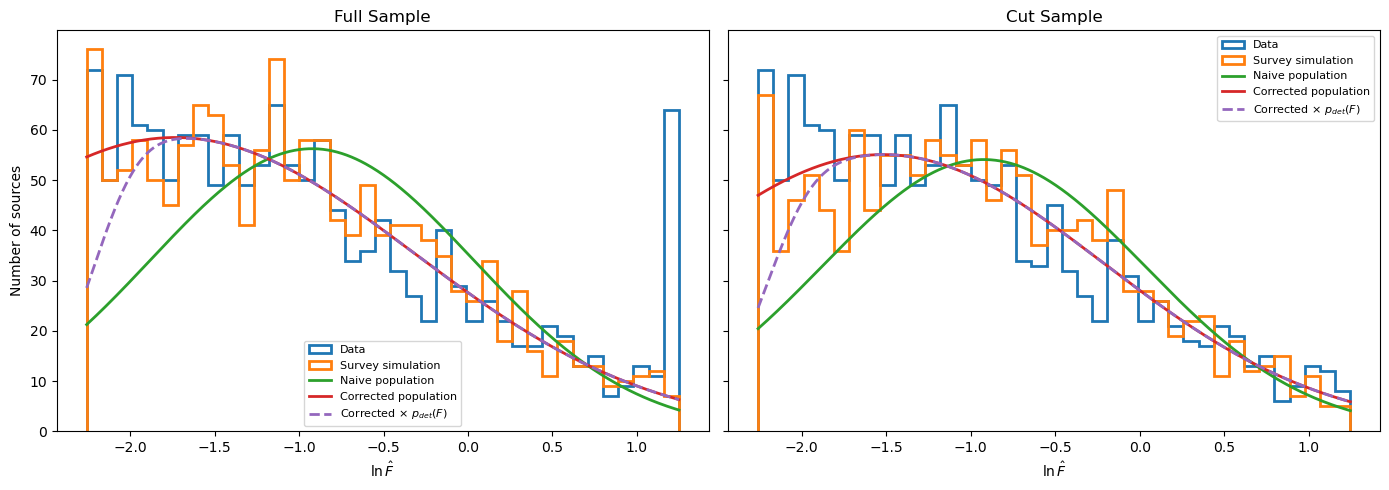

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for panel, counts, mu_n, sig_n, mu_c, sig_c, fdet_c, Ntrue_c, title in [

    (ax[0], n,
     mu_naive, sigma_naive,
     mu_sel, sigma_sel,
     fdet_best, Ntrue,
     "Full Sample"),

    (ax[1], n_cut,
     mu_naive_cut, sigma_naive_cut,
     mu_sel_cut, sigma_sel_cut,
     fdet_best_cut, Ntrue_cut,
     "Cut Sample")

]:

    lnFhat = np.log((counts - nu) / eps)

    bins = np.linspace(lnFhat.min(), lnFhat.max(), 40)

    x = np.linspace(bins.min(), bins.max(), 500)
    dx = bins[1] - bins[0]

    Ndet = len(counts)

    naive_curve = Ndet * norm.pdf(x, mu_n, sig_n) * dx

    corr_curve = Ntrue_c * norm.pdf(x, mu_c, sig_c) * dx

    rng = np.random.default_rng(11326)

    lnF_true = rng.normal(mu_c, sig_c, size=int(round(Ntrue_c)))
    F_true = np.exp(lnF_true)

    n_sim = rng.poisson(eps * F_true + nu)

    mask = n_sim > 32

    lnFhat_sim = np.log((n_sim[mask] - nu) / eps)

    pdet_curve = norm.pdf(x, mu_c, sig_c) * poisson.sf(32, eps * np.exp(x) + nu)
    pdet_curve *= Ntrue_c * dx

    panel.hist(lnFhat, bins=bins, histtype="step", linewidth=2, label="Data")

    panel.hist(lnFhat_sim,
               bins=bins,
               histtype="step",
               linewidth=2,
               label="Survey simulation")

    panel.plot(x, naive_curve, lw=2, label="Naive population")

    panel.plot(x, corr_curve, lw=2, label="Corrected population")

    panel.plot(x,
               pdet_curve,
               "--",
               lw=2,
               label=r"Corrected × $p_{det}(F)$")

    panel.set_title(title)
    panel.set_xlabel(r"$\ln \hat{F}$")

ax[0].set_ylabel("Number of sources")

ax[0].legend(fontsize=8)
ax[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

**ANSWER (the two fits, f_det and the number missed, then the explanation):**

**Fits**

**n**: mu = -1.7347 +/- 0.0500, sigma = 1.4167 +/- 0.0213

**n_cut**: mu = -1.5202 +/- 0.0400, sigma = 1.3097 +/- 0.0262

**Detection**: **n f_det** = 65.01% (807 sources missed), **n_cut f_det** = 71.80% (567 sources missed)

1. When plotting the histogram for my values, I found two notable things. There is a pile up of values at the threshold, which is expected due to the Eddington bias. I also found an unexpected spike of my counts at max (800). Which disrupts the downward trend. It effects 56 sources (3.73%). I've decided to run my fits on the original counts and excluding those 58 sources.
2. The flux is detected 50% of the time at F = ~0.1023.
3.
   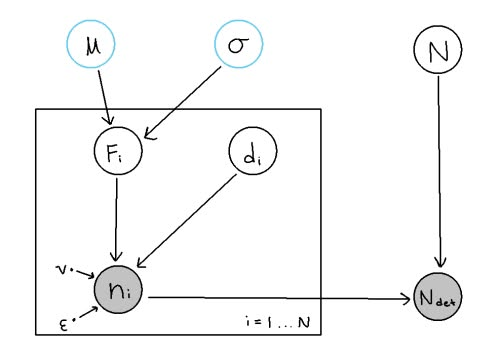
4. Uncertainties calculated through curvature. f_det is the percentage of photons detected out of the estimated true population. The original survey missed 807 sources while the modified survey missed 567 sources.
5. The corrected population times $p_{\rm det}(F)$ fit doesn't match with the survey data because of the Eddington bias. There is an unintented build up of points at the threshold because of noise. Ignoring the detector biased $\mu$ and $\sigma$ to the right.

## Part 3: A supernova in two dimensions (25%)

This one is real. The Carnegie Supernova Project (CSP-I) observed nearby Type Ia supernovae in six optical bands, from $u$ (364 nm) to $i$ (761 nm). Look up your supernova and your held-out band in `08/data/csp_assignments.csv`. Your light curve is `08/data/csp/<SN>.csv`, with columns `mjd`, `band`, `wavelength_A` (the band's effective wavelength), `flux_ujy` and `flux_err_ujy` (flux density in μJy), and the magnitudes they came from. The header gives the redshift and the date of maximum light in $B$. Data: Krisciunas et al. 2017, AJ 154, 211 (CC BY 4.0; credit the Carnegie Supernova Project).

Work in rest-frame phase, $(\mathrm{MJD} - T_{B\,\rm max})/(1+z)$, from $-10$ to $+40$ days, and divide every flux by the peak $B$ flux. Note that `V0`, `V1` and `V` are three versions of the same filter (within 32 Å) - treat them as one band, $V$.

A supernova's light curves in neighboring bands look alike, so a Gaussian process in **two** inputs, phase and wavelength, can learn all six at once and predict a band it never saw.

1. Plot every band against phase.
2. Fit a GP to the flux as a function of (phase, wavelength) using every band **except** your held-out one, with wavelength in microns (so both inputs are numbers of order 1-50). Use a kernel with its own length scale in phase and in wavelength (an anisotropic squared-exponential) times a fitted amplitude, each point's own measurement error, and a small white-noise term that you also fit. Fit the hyperparameters by maximizing the marginal likelihood (as in Lab 07), from more than one start. `sklearn`'s `GaussianProcessRegressor` (with `alpha` set to the squared errors, `normalize_y=False`, and `ConstantKernel` times `RBF` plus `WhiteKernel`) or your own Cholesky code from Lab 07 are both fine. Report the two length scales, and comment on what each means physically for a supernova.
3. Predict your held-out band at its epochs, with the GP's $1\sigma$ band, and plot it over the data. Report the rms residual as a fraction of the peak, and the fraction of held-out points within $1\sigma$ (add the GP's variance and the measurement variance). Does the GP's error bar look reasonable?
4. Now hold out $u$ instead, and report the same two numbers. Why is this so much harder? Think particularly about what the kernel assumes, and how far $u$ is from the other bands compared with your first held-out band.

In [20]:
# Part 3: your work here
asg = pd.read_csv(LAB + 'csp_assignments.csv')
SN, HOLD = asg.loc[asg.netid == NETID, ['sn', 'holdout_band']].iloc[0]
path = LAB + f'csp/{SN}.csv'
hdr = [l for l in open(path) if l.startswith('#')]          # the header lines: source, license, redshift, date of B maximum
z = float([l for l in hdr if 'z_helio' in l][0].split(':')[-1])
tmax = float([l for l in hdr if 'B-max MJD' in l][0].split(':')[1].split('+/-')[0])
d = pd.read_csv(path, comment='#')
d['band'] = d['band'].replace({'V0': 'V', 'V1': 'V'})   # V0, V1 and V are the same filter - treat them as one band
print(f'{SN}: z = {z}, B maximum at MJD {tmax}, {len(d)} points; held-out band: {HOLD}')

SN2008gp: z = 0.0334, B maximum at MJD 54778.82, 113 points; held-out band: r


In [21]:
d[0:5]

,mjd,band,wavelength_A,flux_ujy,flux_err_ujy,mag,mag_err
0,54768.25,u,3639.3,151.8,2.66,18.505,0.019
1,54768.25,B,4350.6,275.7,2.79,17.924,0.011
2,54768.25,V,5375.2,261.8,2.65,17.875,0.011
3,54768.25,r,6223.3,255.9,3.06,17.886,0.013
4,54768.25,i,7609.2,197.7,2.73,18.159,0.015


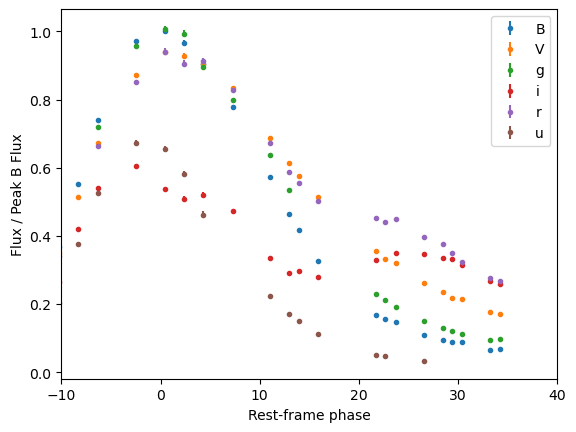

Held out band: r


In [22]:
#1
d['phase'] = (d['mjd'] - tmax) / (1 + z)

Bpeak = d.loc[d["band"] == "B", "flux_ujy"].max()

for band, g in d.groupby("band"):
    plt.errorbar(g["phase"],
                 g["flux_ujy"]/Bpeak,
                 yerr=g["flux_err_ujy"]/Bpeak,
                 fmt="o",
                 ms=3,
                 label=band)

plt.xlabel("Rest-frame phase")
plt.ylabel("Flux / Peak B Flux")
plt.xlim(-10, 40)
plt.legend()
plt.show()

print("Held out band:", HOLD)

In [23]:
#2
train = d[d["band"] != HOLD].copy()
test = d[d["band"] == HOLD].copy()

train["wave_um"] = train["wavelength_A"]/1e4
test["wave_um"] = test["wavelength_A"]/1e4

train["flux_norm"] = train["flux_ujy"]/Bpeak
train["fluxerr_norm"] = train["flux_err_ujy"]/Bpeak

test["flux_norm"] = test["flux_ujy"]/Bpeak
test["fluxerr_norm"] = test["flux_err_ujy"]/Bpeak

Xtrain = np.column_stack([train["phase"], train["wave_um"]])
ytrain = train["flux_norm"].values
yerr = train["fluxerr_norm"].values

kernel = (ConstantKernel(1.0, (1e-3, 1e3))
          * RBF([10.0, 0.3], length_scale_bounds=(1e-2, 1e2))
          + WhiteKernel(1e-3, noise_level_bounds=(1e-8, 1)))

best_gp = None
best_lml = -np.inf

for seed in range(10):

    gp = GaussianProcessRegressor(kernel=kernel, alpha=yerr**2, normalize_y=False, n_restarts_optimizer=1, random_state=seed)
    gp.fit(Xtrain, ytrain)

    if gp.log_marginal_likelihood_value_ > best_lml:
        best_lml = gp.log_marginal_likelihood_value_
        best_gp = gp

Xtest = np.column_stack([test["phase"], test["wave_um"]])

pred, pred_err = best_gp.predict(Xtest, return_std=True)

print(best_gp.kernel_)
print(f'log marginal likelihood = {best_lml:.2f}')

0.325**2 * RBF(length_scale=[7.36, 0.114]) + WhiteKernel(noise_level=1.01e-05)
log marginal likelihood = 204.25


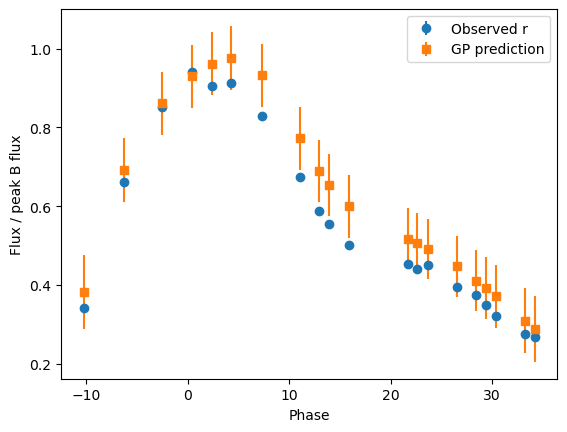

In [24]:
plt.errorbar(test["phase"], test["flux_norm"], yerr=test["fluxerr_norm"], fmt="o", label="Observed r")
plt.errorbar(test["phase"], pred, yerr=pred_err, fmt="s", label="GP prediction")

plt.xlabel("Phase"), plt.ylabel("Flux / peak B flux")
plt.legend()
plt.show()

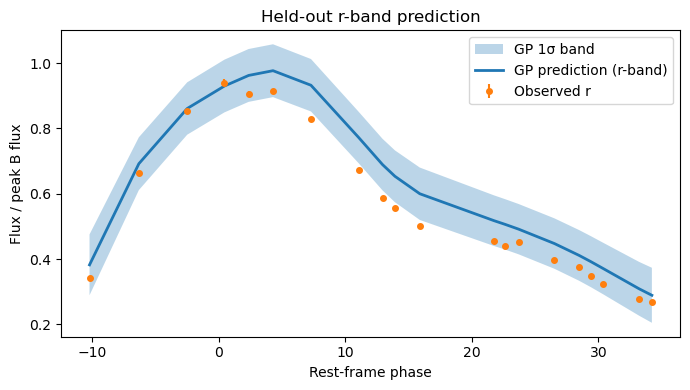

In [25]:
#3
idx = np.argsort(test["phase"].values)

phase_plot = test["phase"].values[idx]
pred_plot = pred[idx]
pred_err_plot = pred_err[idx]

plt.figure(figsize=(7, 4))

plt.fill_between(phase_plot, pred_plot - pred_err_plot, pred_plot + pred_err_plot, alpha=0.3, label="GP 1σ band")

plt.plot(phase_plot, pred_plot, lw=2, label=f"GP prediction ({HOLD}-band)")

plt.errorbar(test["phase"], test["flux_norm"], yerr=test["fluxerr_norm"], fmt="o", ms=4, label=f"Observed {HOLD}")

plt.title(f"Held-out {HOLD}-band prediction"), plt.xlabel("Rest-frame phase"), plt.ylabel("Flux / peak B flux")
plt.legend()
plt.tight_layout()
plt.show()

In [26]:
resid = test["flux_norm"].values - pred

rms_frac_peak = np.sqrt(np.mean(resid**2))

tot_sigma = np.sqrt(pred_err**2 + test["fluxerr_norm"].values**2)

within_1sigma = np.mean(np.abs(resid) <= tot_sigma)

print("Held out band:", HOLD)
print(f"RMS residual / peak B flux = {rms_frac_peak:.4f}")
print(f"Fraction within 1σ = {within_1sigma:.3f}")

print(f"Number of held-out points = {len(test)}")
print("Expected fraction for prediction = ~0.68")

Held out band: r
RMS residual / peak B flux = 0.0632
Fraction within 1σ = 0.750
Number of held-out points = 20
Expected fraction for prediction = ~0.68


In [27]:
#4
train = d[d["band"] != 'u'].copy()
test = d[d["band"] == 'u'].copy()

train["wave_um"] = train["wavelength_A"]/1e4
test["wave_um"] = test["wavelength_A"]/1e4

train["flux_norm"] = train["flux_ujy"]/Bpeak
train["fluxerr_norm"] = train["flux_err_ujy"]/Bpeak

test["flux_norm"] = test["flux_ujy"]/Bpeak
test["fluxerr_norm"] = test["flux_err_ujy"]/Bpeak

Xtrain = np.column_stack([train["phase"], train["wave_um"]])
ytrain = train["flux_norm"].values
yerr = train["fluxerr_norm"].values

kernel = (ConstantKernel(1.0, (1e-3, 1e3))
          * RBF([10.0, 0.3], length_scale_bounds=(1e-2, 1e2))
          + WhiteKernel(1e-3, noise_level_bounds=(1e-8, 1)))

best_gp = None
best_lml = -np.inf

for seed in range(10):

    gp = GaussianProcessRegressor(kernel=kernel, alpha=yerr**2, normalize_y=False, n_restarts_optimizer=1, random_state=seed)
    gp.fit(Xtrain, ytrain)

    if gp.log_marginal_likelihood_value_ > best_lml:
        best_lml = gp.log_marginal_likelihood_value_
        best_gp = gp

Xtest = np.column_stack([test["phase"], test["wave_um"]])

pred, pred_err = best_gp.predict(Xtest, return_std=True)

print(best_gp.kernel_)
print(f'log marginal likelihood = {best_lml:.2f}')

0.302**2 * RBF(length_scale=[7.5, 0.153]) + WhiteKernel(noise_level=2.34e-05)
log marginal likelihood = 231.19


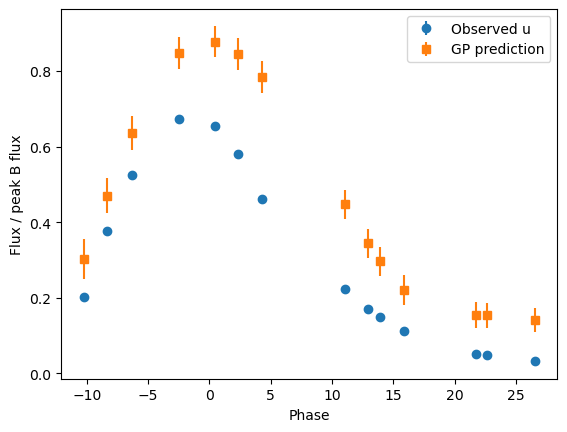

In [28]:
plt.errorbar(test["phase"], test["flux_norm"], yerr=test["fluxerr_norm"], fmt="o", label="Observed u")
plt.errorbar(test["phase"], pred, yerr=pred_err, fmt="s", label="GP prediction")

plt.xlabel("Phase"), plt.ylabel("Flux / peak B flux")
plt.legend()
plt.show()

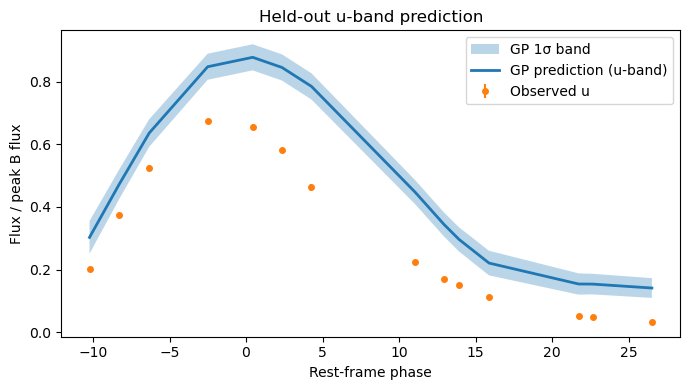

In [29]:
idx = np.argsort(test["phase"].values)

phase_plot = test["phase"].values[idx]
pred_plot = pred[idx]
pred_err_plot = pred_err[idx]

plt.figure(figsize=(7, 4))

plt.fill_between(phase_plot, pred_plot - pred_err_plot, pred_plot + pred_err_plot, alpha=0.3, label="GP 1σ band")

plt.plot(phase_plot, pred_plot, lw=2, label=f"GP prediction ({band}-band)")

plt.errorbar(test["phase"], test["flux_norm"], yerr=test["fluxerr_norm"], fmt="o", ms=4, label=f"Observed {band}")

plt.title(f"Held-out {band}-band prediction"), plt.xlabel("Rest-frame phase"), plt.ylabel("Flux / peak B flux")
plt.legend()
plt.tight_layout()
plt.show()

In [30]:
resid = test["flux_norm"].values - pred

rms_frac_peak = np.sqrt(np.mean(resid**2))

tot_sigma = np.sqrt(pred_err**2 + test["fluxerr_norm"].values**2)

within_1sigma = np.mean(np.abs(resid) <= tot_sigma)

print("Held out band:", band)
print(f"RMS residual / peak B flux = {rms_frac_peak:.4f}")
print(f"Fraction within 1σ = {within_1sigma}")

print(f"Number of held-out points = {len(test)}")
print("Expected fraction for prediction = ~0.68")

Held out band: u
RMS residual / peak B flux = 0.1757
Fraction within 1σ = 0.0
Number of held-out points = 14
Expected fraction for prediction = ~0.68


**ANSWER (length scales, the two held-out tests, then why u is harder):**

**Length scales** = 7.36, 0.114, **r-band**: RMS = 0.0632, Fraction within 1σ = 0.750, **u-band**: RMS  = 0.1757, Fraction within 1σ = 0.000

$u$ as a band is much further from all the other bands. In comparison to the $r$ band which has much more overlap with the rest. The kernel here assumes the prior mean to be constant and zero. Which causes trouble with a band like $u$ that is pulled away from the rest.

## Part 4: AI-use appendix and verification plan (10%)

1. **AI use**: which tools, for what, what they got wrong, and how you caught it. "I didn't use any" is fine if true.
2. **Reflection**: what would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing.
3. **Verification plan**: the checks you ran before trusting your Part 1 and Part 2 numbers, and what failure would have looked like for each. Part 1.3 is already one. For Part 2, one check to consider is to simulate a catalog yourself with a $\mu$ and $\sigma$ you choose, through the same detector, run both fits on it, and see whether the corrected fit gets back what you put in and the naive one doesn't. One catalog isn't enough - comment on how many you'd need.

**AI-USE APPENDIX:**

I used Copilot for the lab. I asked questions to check my understanding of the assignment and my approach to each of the problems. At times, it did make incorrect suggestions for improving my work, such as with my probabilistic graphical models. For certain sections of the assignment where Copilot wrote the code, there were times where it would go against the assignment directions.

**REFLECTION:**

If I had not checked the AI output, I would have incorrectly written my probabilistic graphical models. Which in turn would have negatively impacted 1.2 of the assignment. It also at one point incorrect set the threshold for 2.3 despite the 2.2 results. Resulting in numbers that didn't make sense.

**VERIFICATION PLAN:**

For my verification plan, I did the suggested catalog simulation with chosen $\mu$ and $\sigma$. I would need likely at least 50 catalogs for proper verification. I am looking to see the corrected fit get back what I put in while the naive fit does not.

In [31]:
mu_true = -2
sigma_true = 1
Ntrue_sim = 3000

lnF_true = rng.normal(mu_true, sigma_true, size=Ntrue_sim)
F_true = np.exp(lnF_true)

n_all = rng.poisson(eps * F_true + nu)

n_verify = n_all[n_all > 32]

print(f"True population: {Ntrue_sim}")
print(f"Detected sources: {len(n_verify)}")

logpois_verify = poisson.logpmf(
    n_verify[:, None],
    lam_grid[None, :]
)

def loglike_catalog_verify(mu, sigma):

    if sigma <= 0:
        return -np.inf

    lnprior = (
        -0.5 * ((lnF_grid - mu) / sigma) ** 2
        - np.log(sigma * np.sqrt(2 * np.pi))
    )

    logLi = (
        logsumexp(logpois_verify + lnprior[None, :], axis=1)
        + np.log(dlnF)
    )

    return np.sum(logLi)

def nll_naive_verify(theta):

    mu, lnsig = theta
    sigma = np.exp(lnsig)

    if sigma < 0.05 or sigma > 5:
        return 1e30

    if mu < -10 or mu > 5:
        return 1e30

    ll = loglike_catalog_verify(mu, sigma)

    if not np.isfinite(ll):
        return 1e30

    return -ll

def nll_sel_verify(theta):

    mu, lnsig = theta
    sigma = np.exp(lnsig)

    if sigma < 0.05 or sigma > 5:
        return 1e30

    if mu < -10 or mu > 5:
        return 1e30

    ll = loglike_catalog_verify(mu, sigma)

    if not np.isfinite(ll):
        return 1e30

    fd = fdet(mu, sigma)

    if (not np.isfinite(fd)) or (fd <= 0):
        return 1e30

    return -(ll - len(n_verify) * np.log(fd))

mu0 = np.log(np.median((n_verify - nu) / eps))

fit_naive = minimize(
    nll_naive_verify,
    x0=(mu0, np.log(1.0)),
    method="Nelder-Mead"
)

fit_sel = minimize(
    nll_sel_verify,
    x0=fit_naive.x,
    method="Nelder-Mead"
)

mu_naive_verify = fit_naive.x[0]
sigma_naive_verify = np.exp(fit_naive.x[1])

mu_sel_verify = fit_sel.x[0]
sigma_sel_verify = np.exp(fit_sel.x[1])

print("\nTruth")
print(f"mu = {mu_true:.4f}")
print(f"sigma = {sigma_true:.4f}")

print("\nNaive recovery")
print(f"mu = {mu_naive_verify:.4f}")
print(f"sigma = {sigma_naive_verify:.4f}")

print("\nSelection-corrected recovery")
print(f"mu = {mu_sel_verify:.4f}")
print(f"sigma = {sigma_sel_verify:.4f}")

True population: 3000
Detected sources: 1837

Truth
mu = -2.0000
sigma = 1.0000

Naive recovery
mu = -1.3608
sigma = 0.6392

Selection-corrected recovery
mu = -1.9131
sigma = 0.9501


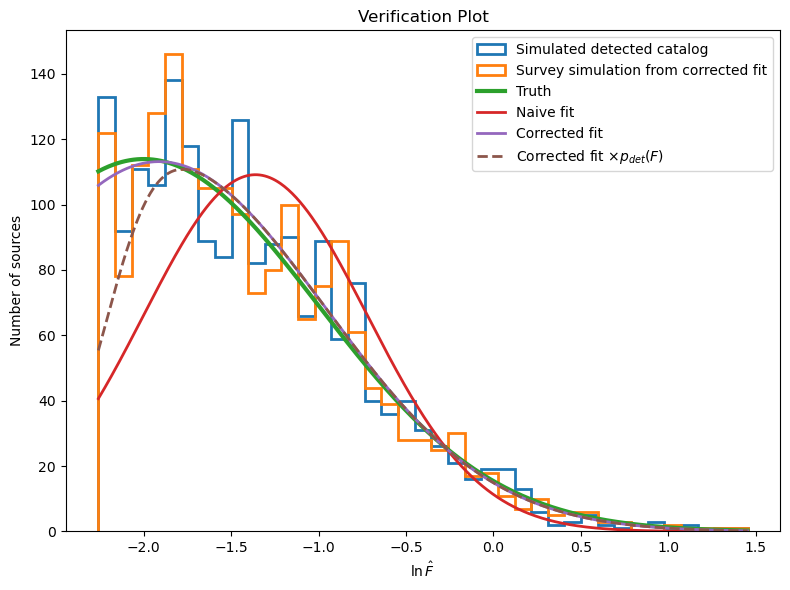

In [32]:
lnFhat_verify = np.log((n_verify - nu) / eps)
bins = np.linspace(lnFhat_verify.min(), lnFhat_verify.max(), 40)

x = np.linspace(bins.min(), bins.max(), 500)
dx = bins[1] - bins[0]

Ndet_verify = len(n_verify)

fdet_verify = fdet(mu_sel_verify, sigma_sel_verify)

Ntrue_verify = Ndet_verify / fdet_verify

naive_curve_verify = (
    Ndet_verify
    * norm.pdf(x, mu_naive_verify, sigma_naive_verify)
    * dx
)

corr_curve_verify = (
    Ntrue_verify
    * norm.pdf(x, mu_sel_verify, sigma_sel_verify)
    * dx
)

truth_curve = (
    Ntrue_sim
    * norm.pdf(x, mu_true, sigma_true)
    * dx
)

rng = np.random.default_rng(54321)

lnF_true_check = rng.normal(
    mu_sel_verify,
    sigma_sel_verify,
    size=int(round(Ntrue_verify))
)

F_true_check = np.exp(lnF_true_check)

n_sim_check = rng.poisson(eps * F_true_check + nu)

mask = n_sim_check > 32

lnFhat_sim = np.log((n_sim_check[mask] - nu) / eps)

pdet_curve_verify = (
    norm.pdf(x, mu_sel_verify, sigma_sel_verify)
    * poisson.sf(32, eps * np.exp(x) + nu)
)

pdet_curve_verify *= Ntrue_verify * dx

plt.figure(figsize=(8, 6))

plt.hist(lnFhat_verify,bins=bins, histtype="step", linewidth=2, label="Simulated detected catalog")
plt.hist(lnFhat_sim, bins=bins, histtype="step", linewidth=2,label="Survey simulation from corrected fit")

plt.plot(x, truth_curve, lw=3, label="Truth")
plt.plot(x, naive_curve_verify, lw=2, label="Naive fit")
plt.plot(x, corr_curve_verify, lw=2, label="Corrected fit")
plt.plot(x, pdet_curve_verify, "--", lw=2, label=r"Corrected fit $\times p_{det}(F)$")

plt.xlabel(r"$\ln \hat{F}$")
plt.ylabel("Number of sources")
plt.title("Verification Plot")
plt.legend()
plt.tight_layout()
plt.show()